# Lab 6: Logistic Regression for Classification Problems
**CS106: Basics of Machine Learning & Applications**

Datasets: `pima-indians-diabetes` (Q1) and `card_transdata_fraud.csv` (Q2).

## Imports

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    auc
)

from sklearn.dummy import DummyClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Q1. Logistic Regression on the Pima Indians Diabetes dataset

### Q1 (a) Read, inspect, identify target/features, class distribution

In [ ]:

df = pd.read_csv('/content/drive/MyDrive/DTU/AIML/LAB/datasets/pima-indians-diabetes.csv')

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (768, 9)

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Class                     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


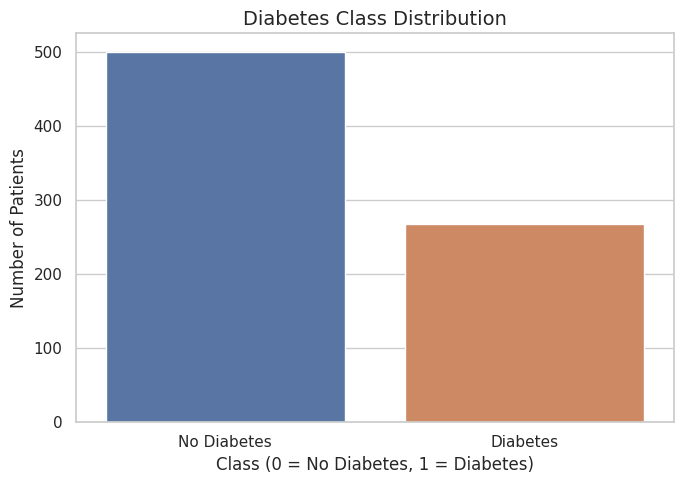

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    legend=False
)

plt.title("Diabetes Class Distribution", fontsize=14)
plt.xlabel("Class (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.tight_layout()
plt.show()

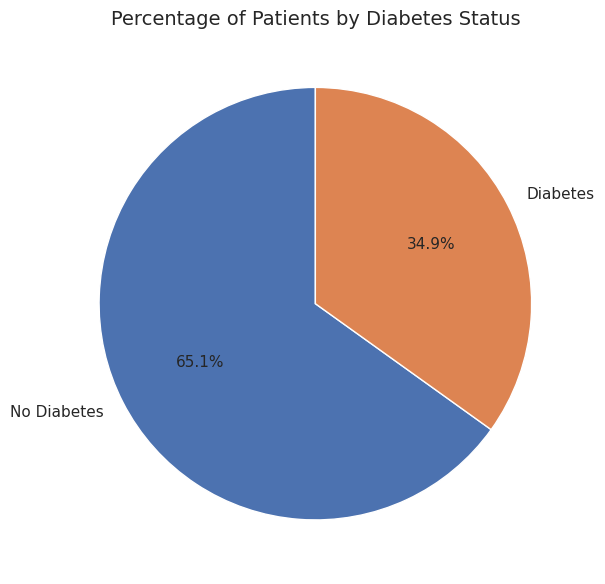

In [ ]:

class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 6))

plt.pie(
    class_counts,
    labels=["No Diabetes", "Diabetes"],
    autopct="%1.1f%%",
    startangle=90,
    textprops={"fontsize": 11}
)

plt.title("Percentage of Patients by Diabetes Status", fontsize=14)
plt.tight_layout()
plt.show()

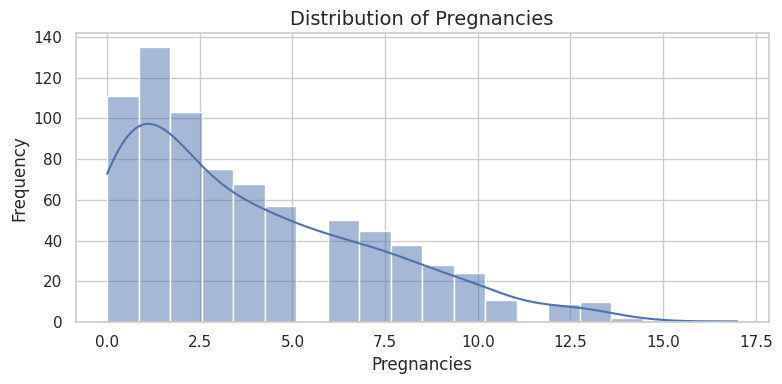

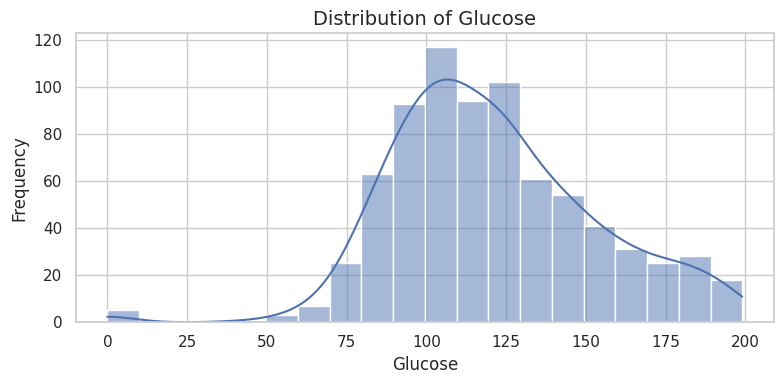

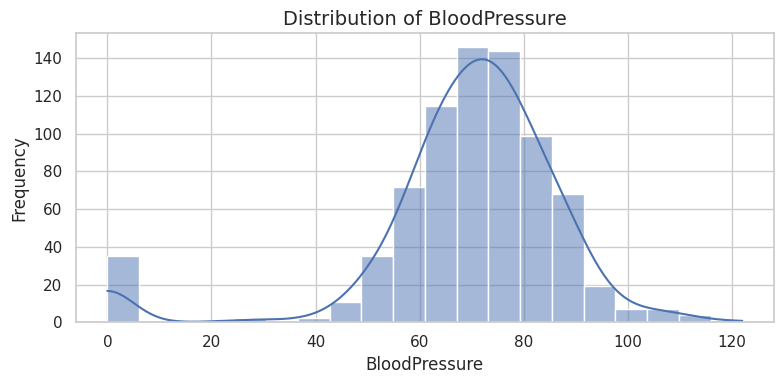

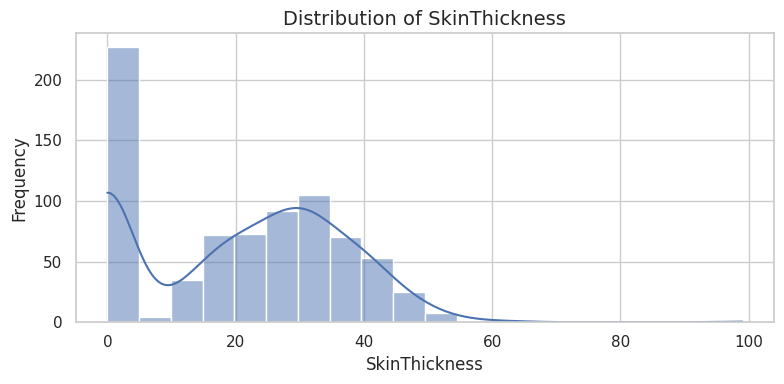

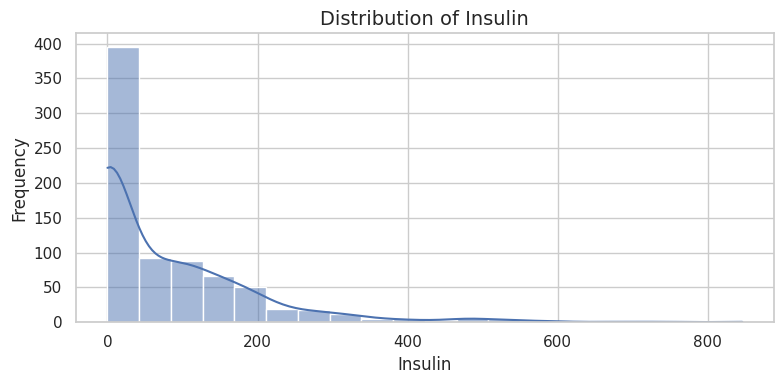

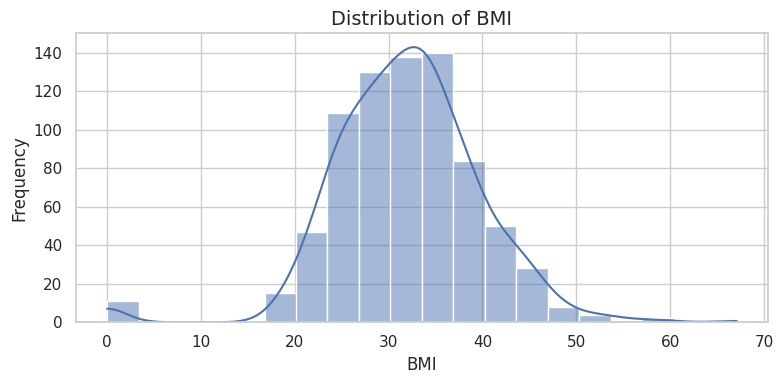

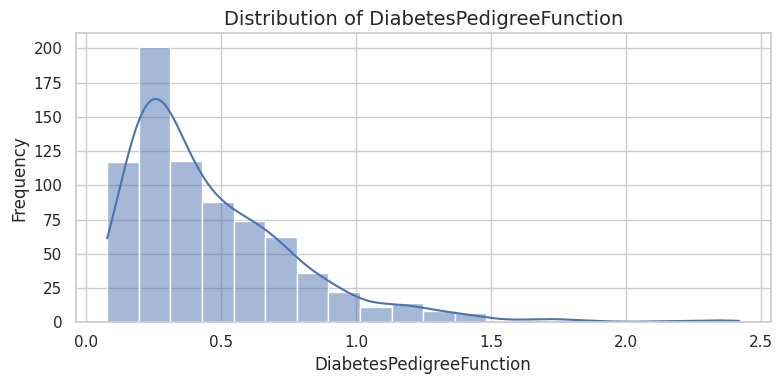

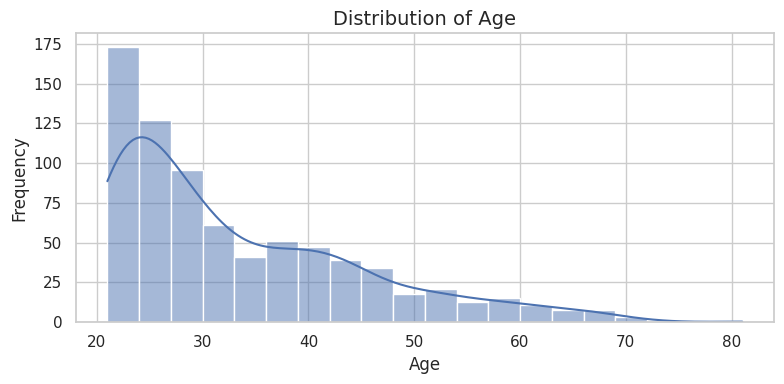

In [ ]:

features = df.drop(columns="Class").columns

for feature in features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {feature}", fontsize=14)
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

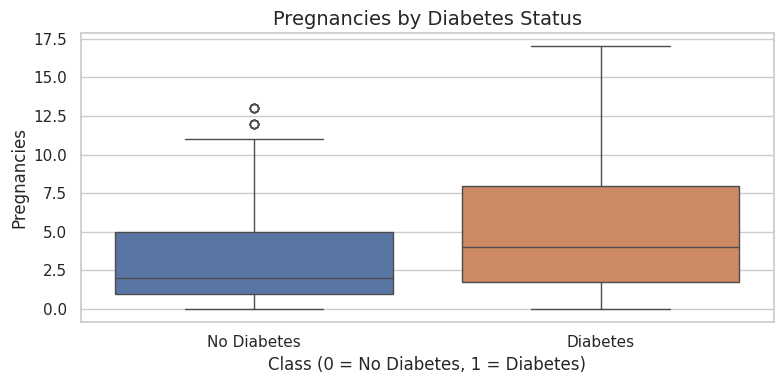

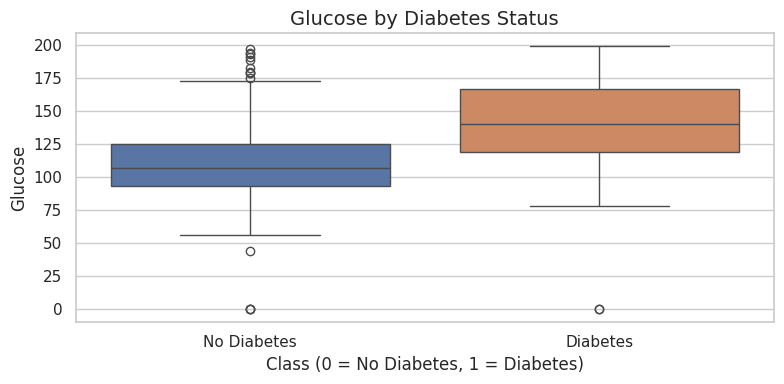

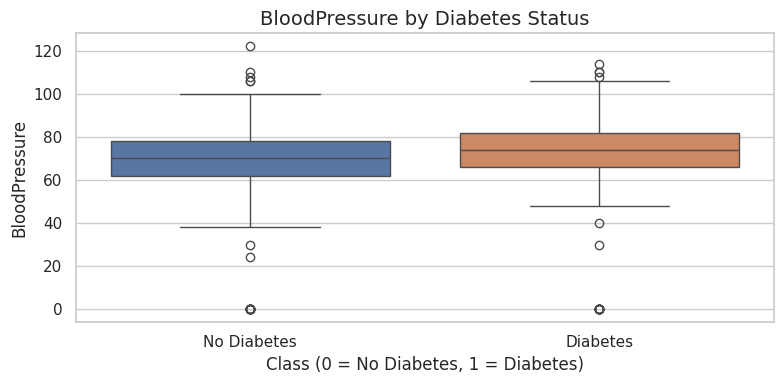

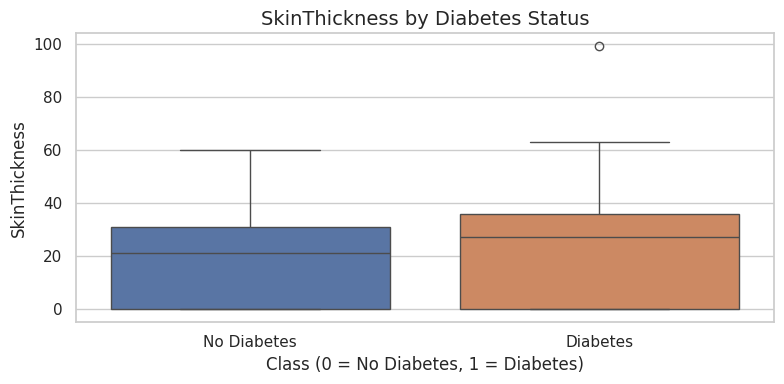

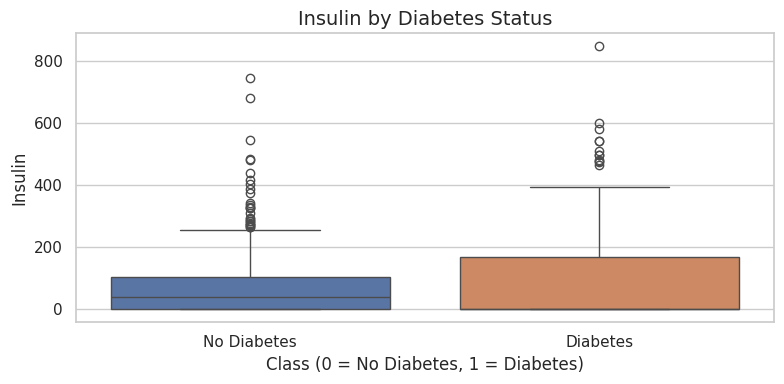

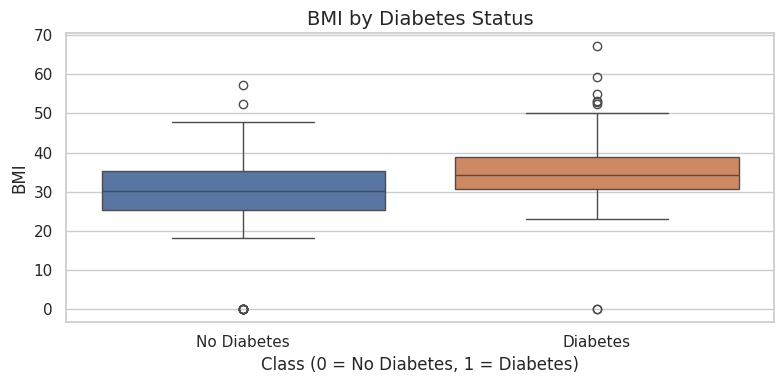

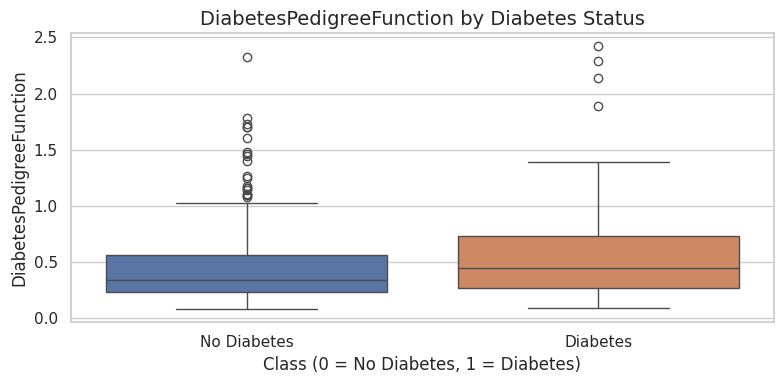

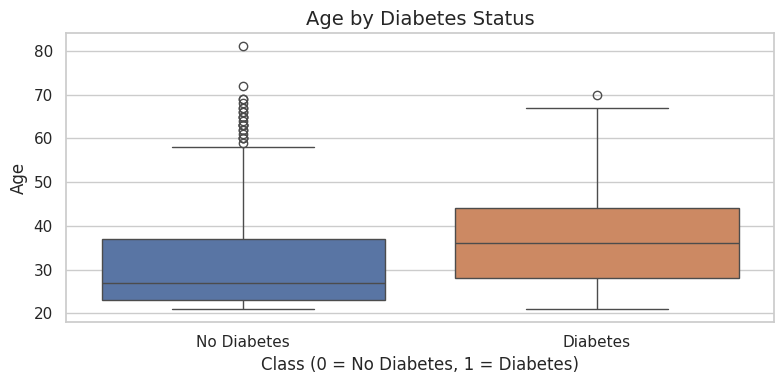

In [ ]:

for feature in features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        legend=False
    )

    plt.title(f"{feature} by Diabetes Status", fontsize=14)
    plt.xlabel("Class (0 = No Diabetes, 1 = Diabetes)")
    plt.ylabel(feature)
    plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
    plt.tight_layout()
    plt.show()

### Q1 (b) Count impossible zeros, treat as missing, handle them (median imputation is done after the split in (c))

In [ ]:

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_counts = (df[zero_columns] == 0).sum()

print("Zero values in selected medical features:")
display(zero_counts.to_frame(name="Zero Count"))

Zero values in selected medical features:


,Zero Count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


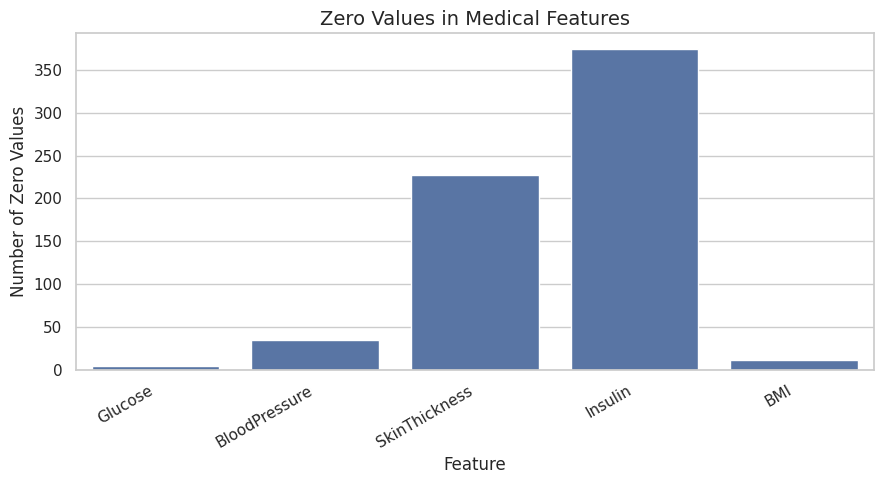

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    x=zero_counts.index,
    y=zero_counts.values
)

plt.title("Zero Values in Medical Features", fontsize=14)
plt.xlabel("Feature")
plt.ylabel("Number of Zero Values")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:

df_clean = df.copy()

df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

print("Missing values after replacing zeros:")
display(df_clean.isna().sum().to_frame(name="Missing Count"))

Missing values after replacing zeros:


,Missing Count
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Class,0


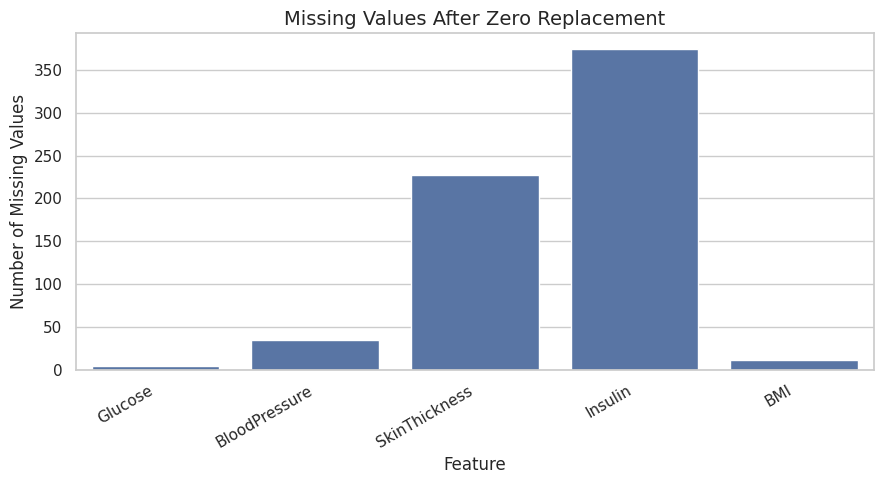

In [ ]:

missing_counts = df_clean.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values
)

plt.title("Missing Values After Zero Replacement", fontsize=14)
plt.xlabel("Feature")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Q1 (c) Stratified 80/20 split (+ median imputation from training data) and standardization

In [ ]:

target = "Class"

X = df_clean.drop(columns=target)
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Calculate medians using training data only
train_medians = X_train.median()

X_train_imp = X_train.fillna(train_medians)
X_test_imp = X_test.fillna(train_medians)

print("Training set shape:", X_train_imp.shape)
print("Test set shape:", X_test_imp.shape)

print("\nRemaining missing values:")
print("Training:", X_train_imp.isna().sum().sum())
print("Test:", X_test_imp.isna().sum().sum())

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest class distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training set shape: (614, 8)
Test set shape: (154, 8)

Remaining missing values:
Training: 0
Test: 0

Training class distribution:
Class
0    0.651
1    0.349
Name: proportion, dtype: float64

Test class distribution:
Class
0    0.649
1    0.351
Name: proportion, dtype: float64


In [ ]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Scaled training set shape:", X_train_scaled.shape)
print("Scaled test set shape:", X_test_scaled.shape)

print("\nTraining feature means (approximately 0):")
print(X_train_scaled.mean(axis=0).round(3))

print("\nTraining feature standard deviations (approximately 1):")
print(X_train_scaled.std(axis=0).round(3))

Scaled training set shape: (614, 8)
Scaled test set shape: (154, 8)

Training feature means (approximately 0):
[-0. -0.  0. -0. -0.  0. -0. -0.]

Training feature standard deviations (approximately 1):
[1. 1. 1. 1. 1. 1. 1. 1.]


### Q1 (d) Unscaled vs scaled data, coefficients and odds ratios

In [ ]:
import warnings

# Unscaled data (max_iter=100 is the default, so warnings may appear)
lr_unscaled = LogisticRegression(random_state=42, max_iter=100)
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    lr_unscaled.fit(X_train_imp, y_train)
    n_warnings = len(w)

# Scaled data
lr_scaled = LogisticRegression(random_state=42, max_iter=100)
with warnings.catch_warnings(record=True) as w2:
    warnings.simplefilter("always")
    lr_scaled.fit(X_train_scaled, y_train)
    n_warnings_scaled = len(w2)

acc_unscaled = accuracy_score(y_test, lr_unscaled.predict(X_test_imp))
acc_scaled = accuracy_score(y_test, lr_scaled.predict(X_test_scaled))

comparison = pd.DataFrame({
    "Model": ["Unscaled", "Scaled"],
    "Warnings": [n_warnings, n_warnings_scaled],
    "Iterations": [lr_unscaled.n_iter_[0], lr_scaled.n_iter_[0]],
    "Test Accuracy": [round(acc_unscaled, 4), round(acc_scaled, 4)]
})
display(comparison)

coef_df = pd.DataFrame({
    "Feature": X_train_imp.columns,
    "Coef (Unscaled)": lr_unscaled.coef_[0].round(4),
    "Coef (Scaled)": lr_scaled.coef_[0].round(4)
})
display(coef_df)

# Odds ratios from the scaled model (e^coefficient)
for feature in ["Glucose", "BMI"]:
    coef = lr_scaled.coef_[0][list(X_train_imp.columns).index(feature)]
    print(f"{feature}: coefficient = {coef:.4f}, odds ratio = {np.exp(coef):.3f}")

,Model,Warnings,Iterations,Test Accuracy
0,Unscaled,2,100,0.7338
1,Scaled,1,8,0.7078


,Feature,Coef (Unscaled),Coef (Scaled)
0,Pregnancies,0.1533,0.3774
1,Glucose,0.0423,1.1826
2,BloodPressure,-0.0066,-0.0441
3,SkinThickness,-0.0060,0.0283
4,Insulin,-0.0015,-0.0661
5,BMI,0.1116,0.6887
6,DiabetesPedigreeFunction,1.4977,0.2333
7,Age,0.0065,0.1478


Glucose: coefficient = 1.1826, odds ratio = 3.263
BMI: coefficient = 0.6887, odds ratio = 1.991


Training the Logistic Regression model on the scaled data (default C = 1):

In [ ]:

from sklearn.linear_model import LogisticRegression

# Initialize the model
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
log_reg.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = log_reg.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")
print("Number of test samples:", len(y_test))
print("Number of predictions:", len(y_pred_lr))

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10])

Logistic Regression model trained successfully!
Number of test samples: 154
Number of predictions: 154

First 10 actual values:
[0 0 0 1 0 0 1 1 0 0]

First 10 predicted values:
[1 0 0 0 0 0 0 1 0 1]


### Q1 (e) Choose C using 5-fold cross-validation
This cell refits `log_reg` with the best C, so the cells below use the best model.

C = 0.001   CV accuracy = 0.6515
C = 0.01    CV accuracy = 0.7671
C = 0.1     CV accuracy = 0.7817
C = 1       CV accuracy = 0.7866
C = 10      CV accuracy = 0.7866
C = 100     CV accuracy = 0.7866

Best C: 1


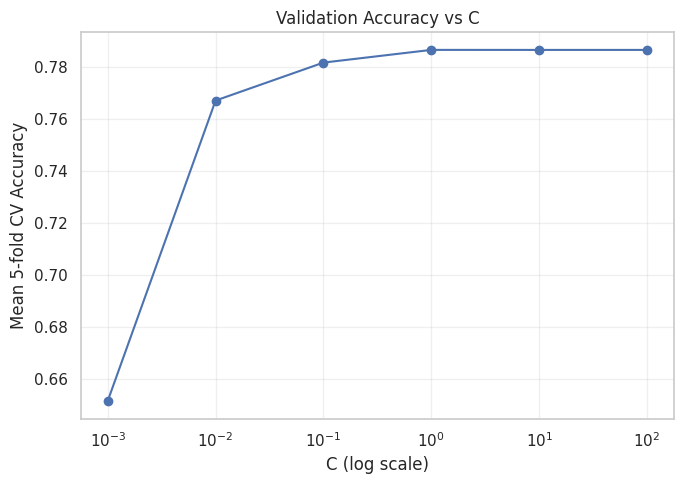

Test accuracy with best C: 0.7078


In [ ]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []
for C in C_values:
    model = LogisticRegression(C=C, max_iter=1000, random_state=42)
    score = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring="accuracy").mean()
    cv_scores.append(score)
    print(f"C = {C:<7} CV accuracy = {score:.4f}")

best_C = C_values[int(np.argmax(cv_scores))]
print("\nBest C:", best_C)

plt.figure(figsize=(7, 5))
plt.plot(C_values, cv_scores, marker="o")
plt.xscale("log")
plt.title("Validation Accuracy vs C")
plt.xlabel("C (log scale)")
plt.ylabel("Mean 5-fold CV Accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Final model with the best C
log_reg = LogisticRegression(C=best_C, max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
print("Test accuracy with best C:", round(accuracy_score(y_test, y_pred_lr), 4))

### Q1 (f) Confusion matrix, precision / recall / F1 by hand, classification_report

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr, zero_division=0)
recall = recall_score(y_test, y_pred_lr, zero_division=0)
f1 = f1_score(y_test, y_pred_lr, zero_division=0)

print("Logistic Regression Evaluation")
print("-" * 35)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression Evaluation
-----------------------------------
Accuracy  : 0.7078
Precision : 0.6000
Recall    : 0.5000
F1-Score  : 0.5455

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



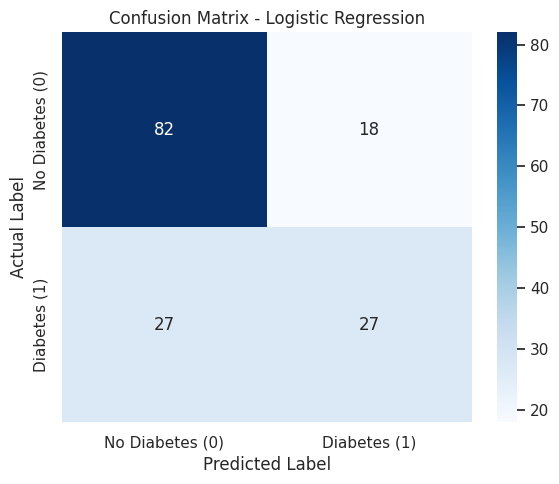

In [ ]:

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes (0)", "Diabetes (1)"],
    yticklabels=["No Diabetes (0)", "Diabetes (1)"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [ ]:
tn, fp, fn, tp = cm.ravel()

accuracy_manual = (tp + tn) / (tp + tn + fp + fn)
precision_manual = tp / (tp + fp)
recall_manual = tp / (tp + fn)
specificity_manual = tn / (tn + fp)
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual)

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Accuracy    = (TP + TN) / total = {accuracy_manual:.4f}")
print(f"Precision   = TP / (TP + FP)    = {precision_manual:.4f}")
print(f"Recall      = TP / (TP + FN)    = {recall_manual:.4f}")
print(f"Specificity = TN / (TN + FP)    = {specificity_manual:.4f}")
print(f"F1-Score    = 2PR / (P + R)     = {f1_manual:.4f}")

TN = 82, FP = 18, FN = 27, TP = 27
Accuracy    = (TP + TN) / total = 0.7078
Precision   = TP / (TP + FP)    = 0.6000
Recall      = TP / (TP + FN)    = 0.5000
Specificity = TN / (TN + FP)    = 0.8200
F1-Score    = 2PR / (P + R)     = 0.5455


**Which error is more costly?** In medical screening a false negative (a diabetic patient told they are healthy) is costlier than a false positive, so recall should be prioritized.

### Q1 (g) ROC curve, AUC, threshold selection

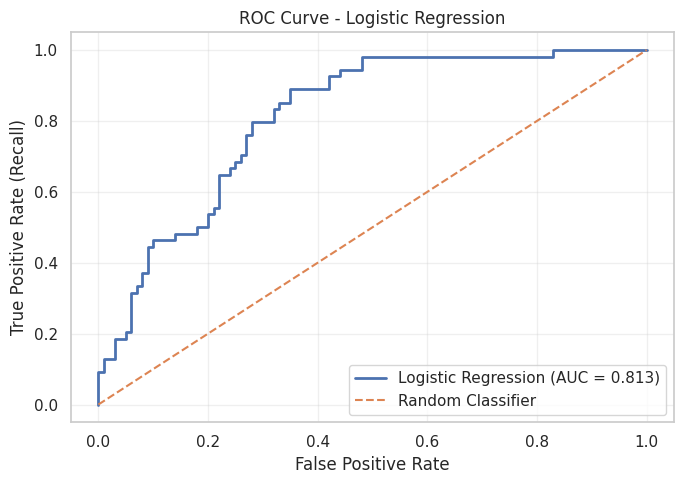

AUC Score: 0.8130


In [ ]:
# Predict probabilities for the positive class (diabetes = 1)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob_lr)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})",
    linewidth=2
)

# Random classifier baseline
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"AUC Score: {auc_score:.4f}")

In [ ]:
rows = []
for t in np.arange(0.1, 1.0, 0.1):
    pred = (y_prob_lr >= t).astype(int)
    rows.append([round(t, 1),
                 precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred, zero_division=0)])
thr_df = pd.DataFrame(rows, columns=["Threshold", "Precision", "Recall"]).round(3)
display(thr_df)

# Best precision among thresholds with recall >= 0.80
ok = thr_df[thr_df["Recall"] >= 0.80]
best_thr = ok.loc[ok["Precision"].idxmax(), "Threshold"]
print("Chosen threshold:", best_thr)

,Threshold,Precision,Recall
0,0.1,0.469,0.981
1,0.2,0.552,0.889
2,0.3,0.597,0.796
3,0.4,0.614,0.648
4,0.5,0.600,0.500
5,0.6,0.641,0.463
6,0.7,0.714,0.370
7,0.8,0.667,0.222
8,0.9,0.833,0.093


Chosen threshold: 0.2


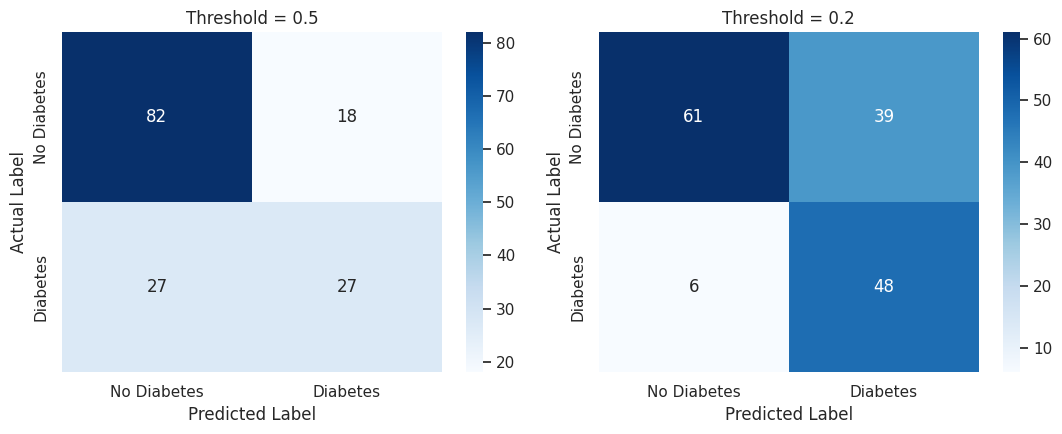

Threshold 0.5: TP=27, FN=27, FP=18, TN=82, Precision=0.600, Recall=0.500
Threshold 0.2: TP=48, FN=6, FP=39, TN=61, Precision=0.552, Recall=0.889


In [ ]:
pred_default = (y_prob_lr >= 0.5).astype(int)
pred_new = (y_prob_lr >= best_thr).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in zip(axes, [pred_default, pred_new],
                           ["Threshold = 0.5", f"Threshold = {best_thr}"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

for name, pred in [("0.5", pred_default), (str(best_thr), pred_new)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Threshold {name}: TP={tp}, FN={fn}, FP={fp}, TN={tn}, "
          f"Precision={tp/(tp+fp):.3f}, Recall={tp/(tp+fn):.3f}")

# Q2. The accuracy trap and class imbalance (card_transdata_fraud)

### Q2 (a) Read data, target, class distribution, predicted accuracy of 'always not fraud'

Shape: (42, 3)


,distance_from_home,ratio_to_median_purchase_price,fraud
0,57.877857,1.945940,0
1,10.829943,1.294219,0
2,5.091079,0.427715,0
3,2.247564,0.362663,0
4,44.190936,2.222767,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 3 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              42 non-null     float64
 1   ratio_to_median_purchase_price  42 non-null     float64
 2   fraud                           42 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 1.1 KB

Class counts:
fraud
0    21
1    21
Name: count, dtype: int64

Class percentages:
fraud
0    50.0
1    50.0
Name: proportion, dtype: float64


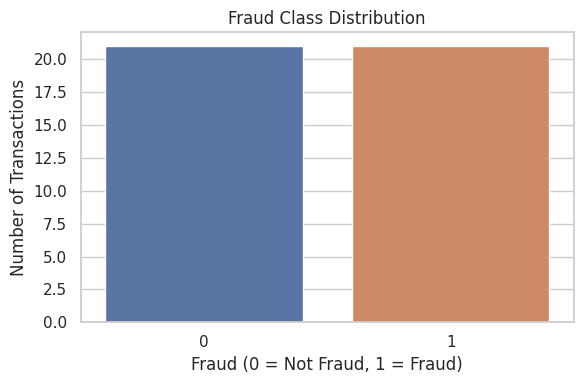

Expected accuracy of 'always not fraud': 0.5


In [ ]:
df2 = pd.read_csv('/content/drive/MyDrive/DTU/AIML/LAB/datasets/card_transdata_fraud.csv')
target2 = "fraud"          # change if your target column has another name

# If the file is too large, take a stratified sample of 100,000 rows
if len(df2) > 100000:
    df2, _ = train_test_split(df2, train_size=100000, stratify=df2[target2], random_state=42)
    print("Sample size used:", len(df2))

print("Shape:", df2.shape)
display(df2.head())
df2.info()

print("\nClass counts:")
print(df2[target2].value_counts())
print("\nClass percentages:")
print((df2[target2].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df2, x=target2, hue=target2, legend=False)
plt.title("Fraud Class Distribution")
plt.xlabel("Fraud (0 = Not Fraud, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Prediction: accuracy of a model that always says "not fraud"
print("Expected accuracy of 'always not fraud':", round(1 - df2[target2].mean(), 4))

### Q2 (b) Stratified split and DummyClassifier baseline

In [ ]:
X2 = df2.drop(columns=target2)
y2 = df2[target2]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.20, random_state=42, stratify=y2)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X2_train, y2_train)
y2_pred_dummy = dummy.predict(X2_test)

print("Dummy Classifier (always predicts 'not fraud')")
print("Accuracy :", round(accuracy_score(y2_test, y2_pred_dummy), 4))
print("Recall   :", round(recall_score(y2_test, y2_pred_dummy, zero_division=0), 4))
print("F1-score :", round(f1_score(y2_test, y2_pred_dummy, zero_division=0), 4))

Dummy Classifier (always predicts 'not fraud')
Accuracy : 0.4444
Recall   : 1.0
F1-score : 0.6154


### Q2 (c) Logistic Regression on scaled features

Logistic Regression (default)
Accuracy : 0.7778
Precision: 1.0
Recall   : 0.5
F1-score : 0.6667


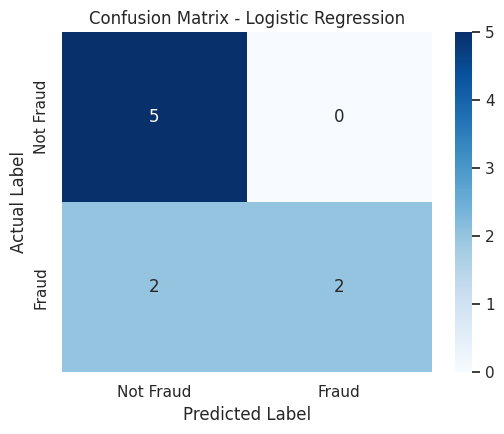

In [ ]:
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

lr2 = LogisticRegression(max_iter=1000, random_state=42)
lr2.fit(X2_train_scaled, y2_train)
y2_pred = lr2.predict(X2_test_scaled)

print("Logistic Regression (default)")
print("Accuracy :", round(accuracy_score(y2_test, y2_pred), 4))
print("Precision:", round(precision_score(y2_test, y2_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y2_test, y2_pred), 4))
print("F1-score :", round(f1_score(y2_test, y2_pred), 4))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y2_test, y2_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Fraud", "Fraud"], yticklabels=["Not Fraud", "Fraud"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Q2 (d) class_weight = 'balanced'

,Model,Accuracy,Precision,Recall,F1-score
0,Default,0.7778,1.0,0.5,0.6667
1,Balanced,0.7778,1.0,0.5,0.6667


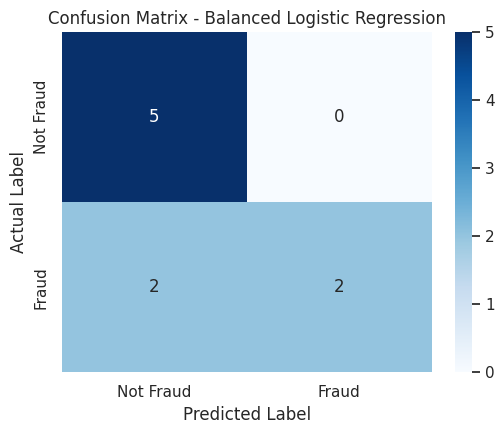

In [ ]:
lr2_bal = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr2_bal.fit(X2_train_scaled, y2_train)
y2_pred_bal = lr2_bal.predict(X2_test_scaled)

compare = pd.DataFrame({
    "Model": ["Default", "Balanced"],
    "Accuracy": [accuracy_score(y2_test, y2_pred), accuracy_score(y2_test, y2_pred_bal)],
    "Precision": [precision_score(y2_test, y2_pred, zero_division=0), precision_score(y2_test, y2_pred_bal)],
    "Recall": [recall_score(y2_test, y2_pred), recall_score(y2_test, y2_pred_bal)],
    "F1-score": [f1_score(y2_test, y2_pred), f1_score(y2_test, y2_pred_bal)]
}).round(4)
display(compare)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y2_test, y2_pred_bal), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Fraud", "Fraud"], yticklabels=["Not Fraud", "Fraud"])
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Q2 (e) Precision-recall vs threshold, ROC-AUC vs PR-AUC

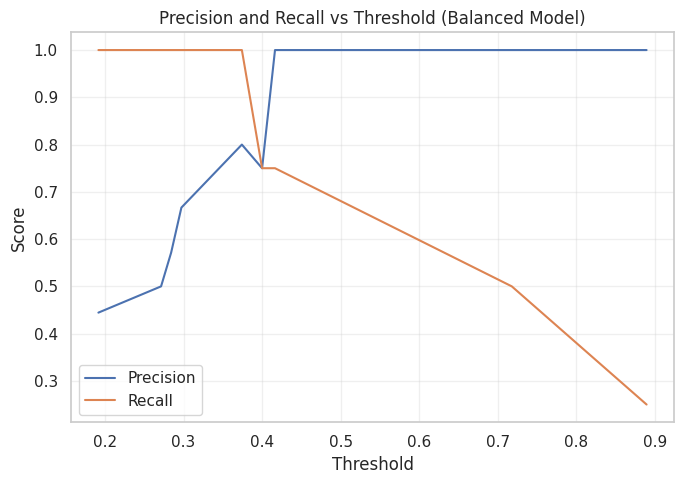

ROC-AUC : 0.9500
PR-AUC  : 0.9437


In [ ]:
y2_prob_bal = lr2_bal.predict_proba(X2_test_scaled)[:, 1]

prec, rec, thr = precision_recall_curve(y2_test, y2_prob_bal)

plt.figure(figsize=(7, 5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.title("Precision and Recall vs Threshold (Balanced Model)")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

roc_auc = roc_auc_score(y2_test, y2_prob_bal)
pr_auc = auc(rec, prec)
print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")

### Q2 (f) Final model and threshold recommendation

Chosen threshold: 0.374
              precision    recall  f1-score   support

   Not Fraud       1.00      0.80      0.89         5
       Fraud       0.80      1.00      0.89         4

    accuracy                           0.89         9
   macro avg       0.90      0.90      0.89         9
weighted avg       0.91      0.89      0.89         9



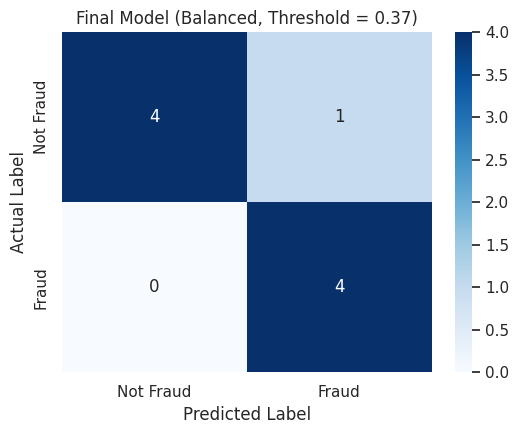

In [ ]:
# Best precision among thresholds that give recall >= 0.90 (change 0.90 if you prefer)
mask = rec[:-1] >= 0.90
best_idx = np.argmax(np.where(mask, prec[:-1], -1))
final_thr = thr[best_idx]
print(f"Chosen threshold: {final_thr:.3f}")

y2_pred_final = (y2_prob_bal >= final_thr).astype(int)
print(classification_report(y2_test, y2_pred_final, target_names=["Not Fraud", "Fraud"]))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y2_test, y2_pred_final), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Fraud", "Fraud"], yticklabels=["Not Fraud", "Fraud"])
plt.title(f"Final Model (Balanced, Threshold = {final_thr:.2f})")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()